<a href="https://colab.research.google.com/github/dunurejoice20/electricity-forecasting./blob/main/electricity-forecasting./notebooks/Copy_of_Dami's_copy_of_the_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import pandas as pd

df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values="?"
)

df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB


In [18]:
df.isnull().sum()

,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979


In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df.dtypes

,0
Date,object
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64


In [21]:
df['Date'] = pd.to_datetime(df['Date'],dayfirst=True)

In [22]:
df.dtypes

,0
Date,datetime64[ns]
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64


In [23]:
df['Time'] = pd.to_datetime(df["Time"], format='%H:%M:%S').dt.time

In [24]:
df.dtypes

,0
Date,datetime64[ns]
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64


In [25]:
df['Datetime'] = pd.to_datetime(
    df['Date'].dt.strftime('%Y-%m-%d') +  '' + df['Time'].astype(str),
    errors='coerce'

)

/tmp/ipykernel_2484/1851200061.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Datetime'] = pd.to_datetime(


In [26]:
df[['Date', 'Time', 'Datetime']].head()

,Date,Time,Datetime
0,2006-12-16,17:24:00,NaT
1,2006-12-16,17:25:00,NaT
2,2006-12-16,17:26:00,NaT
3,2006-12-16,17:27:00,NaT
4,2006-12-16,17:28:00,NaT


In [27]:
df['Hour'] = pd.to_datetime(
    df['Time'],
    format='%H:%M:%S'
).dt.hour

In [28]:
df[['Time', 'Hour', ]].head()

,Time,Hour
0,17:24:00,17
1,17:25:00,17
2,17:26:00,17
3,17:27:00,17
4,17:28:00,17


In [29]:
df['Day'] = df['Date'].dt.day

In [30]:
df[['Date', 'Day']].head()

,Date,Day
0,2006-12-16,16
1,2006-12-16,16
2,2006-12-16,16
3,2006-12-16,16
4,2006-12-16,16


In [31]:
df['Month'] = df['Date'].dt.month

In [32]:
df[['Date', 'Month']].head()

,Date,Month
0,2006-12-16,12
1,2006-12-16,12
2,2006-12-16,12
3,2006-12-16,12
4,2006-12-16,12


In [33]:
df['Day_of_week'] = df['Date'].dt.dayofweek

In [34]:
df[['Date', 'Day_of_week']].head()

,Date,Day_of_week
0,2006-12-16,5
1,2006-12-16,5
2,2006-12-16,5
3,2006-12-16,5
4,2006-12-16,5


In [35]:
df.isnull().sum()

,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979
Datetime,2075259


In [36]:
df['Month'] = df['Date'].dt.month

In [37]:
df[['Date', 'Month']].head()

,Date,Month
0,2006-12-16,12
1,2006-12-16,12
2,2006-12-16,12
3,2006-12-16,12
4,2006-12-16,12


In [38]:
df['DayOfWeek'] = df['Date'].dt.dayofweek

In [39]:
df[['Date', 'DayOfWeek']].head()

,Date,DayOfWeek
0,2006-12-16,5
1,2006-12-16,5
2,2006-12-16,5
3,2006-12-16,5
4,2006-12-16,5


In [40]:
df.isnull().sum()

,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979
Datetime,2075259


In [41]:
df.columns.tolist()

['Date',
 'Time',
 'Global_active_power',
 'Global_reactive_power',
 'Voltage',
 'Global_intensity',
 'Sub_metering_1',
 'Sub_metering_2',
 'Sub_metering_3',
 'Datetime',
 'Hour',
 'Day',
 'Month',
 'Day_of_week',
 'DayOfWeek']

In [42]:
print(df.columns.tolist())

['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Datetime', 'Hour', 'Day', 'Month', 'Day_of_week', 'DayOfWeek']


In [43]:
print(len(df.columns))

15


In [44]:
df.shape

(2075259, 15)

In [45]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime,Hour,Day,Month,Day_of_week,DayOfWeek
0,2006-12-16,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,NaT,17,16,12,5,5
1,2006-12-16,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,NaT,17,16,12,5,5
2,2006-12-16,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,NaT,17,16,12,5,5
3,2006-12-16,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,NaT,17,16,12,5,5
4,2006-12-16,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,NaT,17,16,12,5,5


In [46]:
df.columns[df.columns.duplicated()]

Index([], dtype='object')

In [47]:
print(df[['Date', 'Hour', 'Month', 'DayOfWeek']].head(10))

        Date  Hour  Month  DayOfWeek
0 2006-12-16    17     12          5
1 2006-12-16    17     12          5
2 2006-12-16    17     12          5
3 2006-12-16    17     12          5
4 2006-12-16    17     12          5
5 2006-12-16    17     12          5
6 2006-12-16    17     12          5
7 2006-12-16    17     12          5
8 2006-12-16    17     12          5
9 2006-12-16    17     12          5


In [48]:
print(df.columns.tolist())

['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Datetime', 'Hour', 'Day', 'Month', 'Day_of_week', 'DayOfWeek']


In [49]:
df.columns[df.columns.duplicated()]

Index([], dtype='object')

In [50]:
for i, col in enumerate(df.columns):
  print(i, repr(col))

0 'Date'
1 'Time'
2 'Global_active_power'
3 'Global_reactive_power'
4 'Voltage'
5 'Global_intensity'
6 'Sub_metering_1'
7 'Sub_metering_2'
8 'Sub_metering_3'
9 'Datetime'
10 'Hour'
11 'Day'
12 'Month'
13 'Day_of_week'
14 'DayOfWeek'


In [51]:
df[['Day_of_week', 'DayOfWeek']].head()

,Day_of_week,DayOfWeek
0,5,5
1,5,5
2,5,5
3,5,5
4,5,5


In [52]:
df = df.drop(columns=['DayOfWeek'])

In [53]:
df.columns.tolist()

['Date',
 'Time',
 'Global_active_power',
 'Global_reactive_power',
 'Voltage',
 'Global_intensity',
 'Sub_metering_1',
 'Sub_metering_2',
 'Sub_metering_3',
 'Datetime',
 'Hour',
 'Day',
 'Month',
 'Day_of_week']

In [54]:
df.duplicated().sum()

np.int64(0)

In [55]:
df.isnull().sum()

,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979
Datetime,2075259


In [56]:
df.shape

(2075259, 14)

In [57]:
df.isnull().mean() * 100

,0
Date,0.000000
Time,0.000000
Global_active_power,1.251844
Global_reactive_power,1.251844
Voltage,1.251844
Global_intensity,1.251844
Sub_metering_1,1.251844
Sub_metering_2,1.251844
Sub_metering_3,1.251844
Datetime,100.000000


In [58]:
df = df.drop(columns=['Datetime'])

In [59]:
df.shape

(2075259, 13)

In [60]:
df.dtypes

,0
Date,datetime64[ns]
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64
Hour,int32


In [61]:
df['Time'].head()

,Time
0,17:24:00
1,17:25:00
2,17:26:00
3,17:27:00
4,17:28:00


In [62]:
df['Time'] = pd.to_datetime(df['Time'], format='%H:%M:%S').dt.time

In [63]:
df.dtypes

,0
Date,datetime64[ns]
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64
Hour,int32


In [64]:
df.isnull().sum()

,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979
Hour,0


In [65]:
df[df['Global_active_power'].isnull()].head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,...,Sub_metering_3,Hour,Day,Month,Day_of_week
6839,2006-12-21,11:23:00,NaN,NaN,NaN,...,NaN,11,21,12,3
6840,2006-12-21,11:24:00,NaN,NaN,NaN,...,NaN,11,21,12,3
19724,2006-12-30,10:08:00,NaN,NaN,NaN,...,NaN,10,30,12,5
19725,2006-12-30,10:09:00,NaN,NaN,NaN,...,NaN,10,30,12,5
41832,2007-01-14,18:36:00,NaN,NaN,NaN,...,NaN,18,14,1,6


In [66]:
measurement_cols = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3',
]

df[measurement_cols].isnull().all(axis=1).sum()

np.int64(25979)

In [67]:
df = df.dropna(subset=measurement_cols)

In [68]:
df.shape

(2049280, 13)

In [69]:
df.isnull().sum()

,0
Date,0
Time,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0
Hour,0


In [70]:
df.duplicated().sum()

np.int64(0)

In [71]:
df.dtypes

,0
Date,datetime64[ns]
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64
Hour,int32


In [72]:
df.describe()

,Date,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day,Month,Day_of_week
count,2049280,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,2008-12-01 13:00:00.309181952,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00,1.150391e+01,1.571245e+01,6.454433e+00,2.989276e+00
min,2006-12-16 00:00:00,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00
25%,2007-12-10 00:00:00,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.000000e+00,8.000000e+00,3.000000e+00,1.000000e+00
50%,2008-11-30 00:00:00,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.200000e+01,1.600000e+01,6.000000e+00,3.000000e+00
75%,2009-11-23 00:00:00,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01,1.800000e+01,2.300000e+01,9.000000e+00,5.000000e+00
max,2010-11-26 00:00:00,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01,2.300000e+01,3.100000e+01,1.200000e+01,6.000000e+00
std,NaN,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00,6.925189e+00,8.801670e+00,3.423209e+00,1.997633e+00


In [73]:
df[['Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3',]].min()

,0
Global_active_power,0.076
Global_reactive_power,0.000
Voltage,223.200
Global_intensity,0.200
Sub_metering_1,0.000
Sub_metering_2,0.000
Sub_metering_3,0.000


In [74]:
df[['Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3']].max()

,0
Global_active_power,11.122
Global_reactive_power,1.390
Voltage,254.150
Global_intensity,48.400
Sub_metering_1,88.000
Sub_metering_2,80.000
Sub_metering_3,31.000


In [75]:
df['Date'].min(), df['Date'].max()

(Timestamp('2006-12-16 00:00:00'), Timestamp('2010-11-26 00:00:00'))

In [76]:
df['Date'].is_monotonic_increasing

True

In [77]:
print("Hours below 0:", (df['Hour'] < 0).sum())
print("Hours above 23:", (df['Hour'] > 23).sum())

Hours below 0: 0
Hours above 23: 0


In [78]:
print("Days below 1:", (df['Day'] < 1).sum())
print("Days above 31:", (df['Day'] > 31).sum())

Days below 1: 0
Days above 31: 0


In [79]:
print("Months below 1:", (df['Month'] < 1).sum())
print("Months above 12:", (df['Month'] > 12).sum())

Months below 1: 0
Months above 12: 0


In [80]:
print("Days_of_week below 0:", (df['Day_of_week'] < 0).sum())
print("Days_of_week above 6:", (df['Day_of_week'] > 6).sum())

Days_of_week below 0: 0
Days_of_week above 6: 0


In [81]:
cols = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3',
]

df[cols].lt(0).sum()

,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0


In [82]:
df.shape

(2049280, 13)

In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2049280 entries, 0 to 2075258
Data columns (total 13 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Date                   datetime64[ns]
 1   Time                   object        
 2   Global_active_power    float64       
 3   Global_reactive_power  float64       
 4   Voltage                float64       
 5   Global_intensity       float64       
 6   Sub_metering_1         float64       
 7   Sub_metering_2         float64       
 8   Sub_metering_3         float64       
 9   Hour                   int32         
 10  Day                    int32         
 11  Month                  int32         
 12  Day_of_week            int32         
dtypes: datetime64[ns](1), float64(7), int32(4), object(1)
memory usage: 187.6+ MB


Dami's part of the code below

In [84]:
from sklearn.ensemble import IsolationForest
import numpy as np



features = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]




iso_forest = IsolationForest(n_estimators=100, contamination=0.01, random_state=42, n_jobs=-1)



df['Anomaly'] = iso_forest.fit_predict(df[features])



anomaly_counts = df['Anomaly'].value_counts()
print("Anomaly Detection Summary:")
print(f"Normal data points (1): {anomaly_counts.get(1, 0)}")
print(f"Anomalous data points (-1): {anomaly_counts.get(-1, 0)}")

Anomaly Detection Summary:
Normal data points (1): 2028787
Anomalous data points (-1): 20493


In [85]:
anomalies_df = df[df['Anomaly'] == -1]
display(anomalies_df.head())

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day,Month,Day_of_week,Anomaly
41,2006-12-16,18:05:00,6.052,0.192,232.93,26.2,0.0,37.0,17.0,18,16,12,5,-1
42,2006-12-16,18:06:00,6.752,0.186,232.12,29.0,0.0,36.0,17.0,18,16,12,5,-1
43,2006-12-16,18:07:00,6.474,0.144,231.85,27.8,0.0,37.0,16.0,18,16,12,5,-1
44,2006-12-16,18:08:00,6.308,0.116,232.25,27.0,0.0,36.0,17.0,18,16,12,5,-1
71,2006-12-16,18:35:00,6.072,0.000,232.48,26.4,0.0,27.0,17.0,18,16,12,5,-1


In [86]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

daily_profiles = df.groupby(['Date', 'Hour'])['Global_active_power'].mean().unstack()

daily_profiles = daily_profiles.dropna()

print(f"Created daily profiles shape: {daily_profiles.shape} (Days, Hours)")

scaler = StandardScaler()
scaled_profiles = scaler.fit_transform(daily_profiles)

n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
daily_profiles['Cluster'] = kmeans.fit_predict(scaled_profiles)

print("Days per profile cluster:")
print(daily_profiles['Cluster'].value_counts())

Created daily profiles shape: (1417, 24) (Days, Hours)
Days per profile cluster:
Cluster
1    676
0    671
2     70
Name: count, dtype: int64


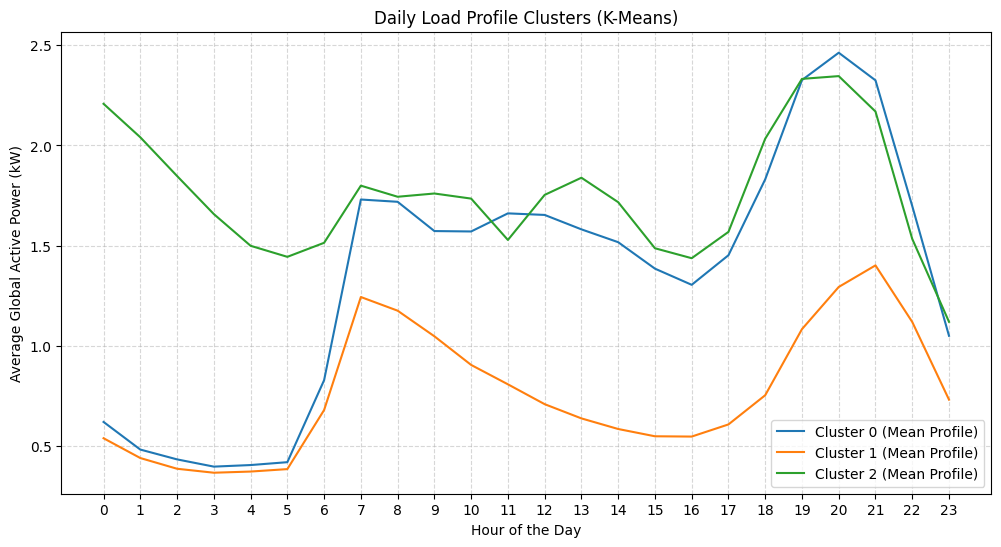

In [87]:
plt.figure(figsize=(12, 6))
for cluster_id in range(n_clusters):
    cluster_data = daily_profiles[daily_profiles['Cluster'] == cluster_id].drop(columns=['Cluster'])
    plt.plot(cluster_data.mean(), label=f'Cluster {cluster_id} (Mean Profile)')

plt.title('Daily Load Profile Clusters (K-Means)')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Global Active Power (kW)')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

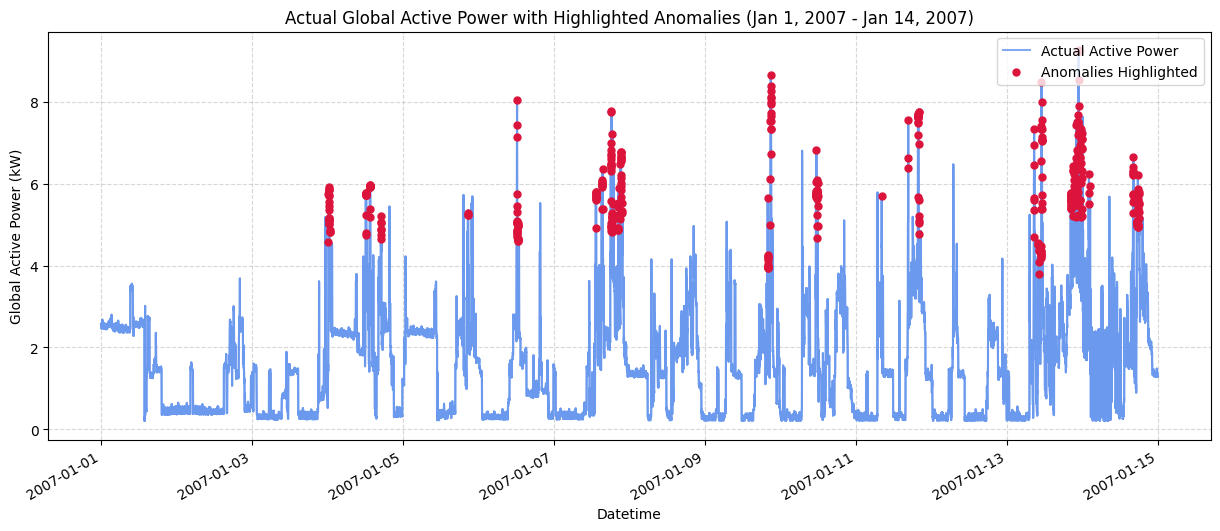

In [88]:
import matplotlib.pyplot as plt
import seaborn as sns


sample_window = df[(df['Date'] >= '2007-01-01') & (df['Date'] <= '2007-01-14')].copy()

sample_window['Datetime'] = pd.to_datetime(sample_window['Date'].astype(str) + ' ' + sample_window['Time'].astype(str))
sample_window = sample_window.sort_values('Datetime')

plt.figure(figsize=(15, 6))
sns.lineplot(x='Datetime', y='Global_active_power', data=sample_window, color='cornflowerblue', alpha=0.8)
plt.plot(sample_window['Datetime'], sample_window['Global_active_power'], label='Actual Active Power', color='cornflowerblue', alpha=0.8)

# Highlight anomalies
anomalies_only = sample_window[sample_window['Anomaly'] == -1]
plt.scatter(anomalies_only['Datetime'], anomalies_only['Global_active_power'], color='crimson', label='Anomalies Highlighted', zorder=5, s=25)

plt.title('Actual Global Active Power with Highlighted Anomalies (Jan 1, 2007 - Jan 14, 2007)')
plt.xlabel('Datetime')
plt.ylabel('Global Active Power (kW)')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.gcf().autofmt_xdate()
plt.show()

Extra features Random Forest regressor to predict Global_active_power using the feature

In [89]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score


predictor_features = [
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3',
    'Hour',
    'Day_of_week'
]

X = df[predictor_features]
y = df['Global_active_power']


X_sub, _, y_sub, _ = train_test_split(X, y, train_size=100000, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X_sub, y_sub, test_size=0.2, random_state=42)

rf_model = RandomForestRegressor(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.4f}")
print(f"R2 Score: {r2:.4f}")

Mean Squared Error: 0.0012
R2 Score: 0.9989


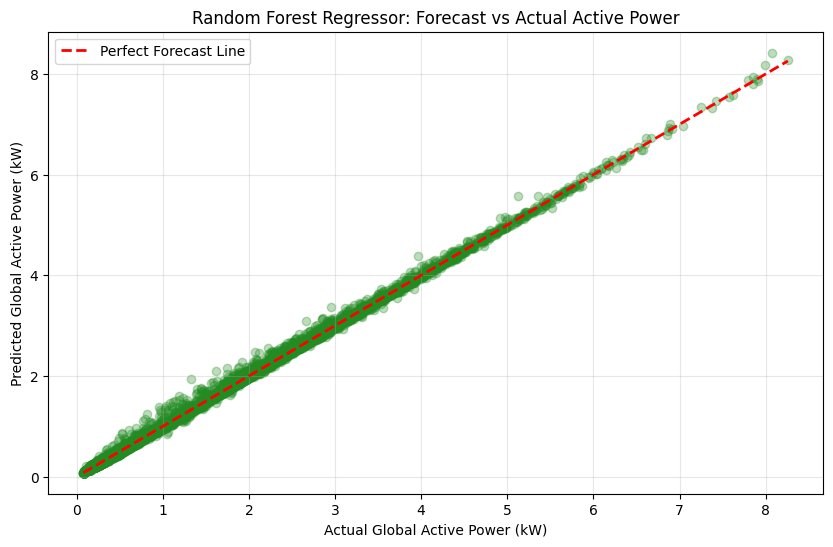

In [90]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='forestgreen')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Forecast Line')
plt.title('Random Forest Regressor: Forecast vs Actual Active Power')
plt.xlabel('Actual Global Active Power (kW)')
plt.ylabel('Predicted Global Active Power (kW)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [91]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importances = rf_model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': predictor_features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("Random Forest Feature Importances:")
display(feature_importance_df)


Random Forest Feature Importances:


,Feature,Importance
2,Global_intensity,0.998730
0,Global_reactive_power,0.000423
1,Voltage,0.000412
3,Sub_metering_1,0.000182
5,Sub_metering_3,0.000095
6,Hour,0.000077
4,Sub_metering_2,0.000053
7,Day_of_week,0.000029


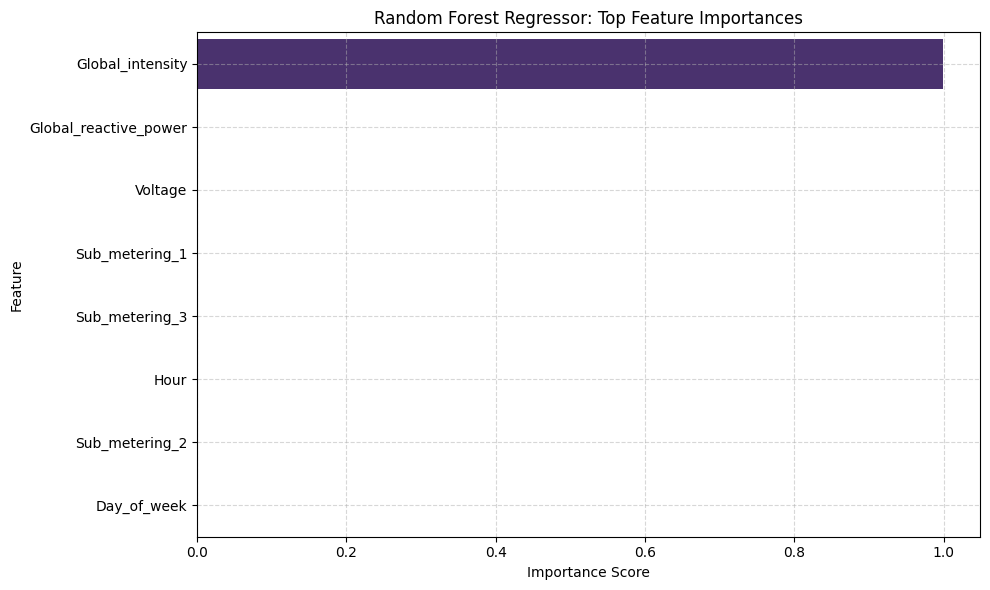

In [92]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis', hue='Feature', legend=False)
plt.title('Random Forest Regressor: Top Feature Importances')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()